# Fantasy Football

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import humanize
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
%matplotlib inline

# pd.set_option('display.max_columns', None)

# Needed for accessing private league
# Pulled using F12 Dev Tools when loading the ESPN fantasy page
cookies = {
  "espn_s2": 'AECMnjlyyYfS8szHcZSE3Xa9mfMaA12A7W5hbsoOPH1poc7CIsf3l5Y6FZRMlPpBa8BTCP4Rb1uztgqwk%2FWKRSEV%2BYQZr2jG0XyjGyz8yZxcne2rc5edV%2FoKD2wW%2BJul9PoxYuEricjtU%2BNn5yx2T32FJ5VuCo0CYMf4bZo0WPU0rSzeAvGlDZ2zaR3J4%2Fny5m4u9OJ1F0E6f97uVurf9XmwKn9uxpdYsa9LSBaYCIA%2BrMGWVLwDA7AozNrZQZTJHDI1nGaR2z3rclHJS6piIYlu25EiAlhDf1ruC%2BY2VRCGohotrgC1dglJQ%2FmDvoR9U7I%3D',
  "SWID": '{3E416C6D-2A8D-4A88-91D4-2F5D31D7C5C2}'
};

# League Definitions
leagueID = 1793518;
year = 2023;

# API SetupS
url = "https://fantasy.espn.com/apis/v3/games/ffl/seasons/" + \
      str(year) + "/segments/0/leagues/" + str(leagueID)

In [2]:
url

'https://fantasy.espn.com/apis/v3/games/ffl/seasons/2023/segments/0/leagues/1793518'

## Manager/User Data

In [3]:
r = requests.get(url, cookies=cookies, params={"view": "mTeam"})
d = r.json()
owners_df = [[
    owner['id'],
    owner['displayName'],
    owner['firstName'],
    owner['lastName']
    ] for owner in d['members']]
owners_df = pd.DataFrame(owners_df, columns=['ID', 'USER_NAME', 'FIRST', 'LAST'])
owners_df['FULL_NAME'] = owners_df['FIRST']+' '+owners_df['LAST']
owners_df

,ID,USER_NAME,FIRST,LAST,FULL_NAME
0,{3E416C6D-2A8D-4A88-91D4-2F5D31D7C5C2},kyleblanks,Kyle,Blankenbeckler,Kyle Blankenbeckler
1,{63AABB56-1CC3-41A8-A6EB-022FCDEA8724},lukeblanks,Luke,Blankenbeckler,Luke Blankenbeckler
2,{6E6F8FB3-37EA-4BCC-ACBE-1867D2B8FBC2},ESPNFAN9968991027,Tara,Leuenberger,Tara Leuenberger
3,{92A7F038-BC40-4001-B18B-C31355F5BD60},jleu3wins,Jesse,Leuenberger,Jesse Leuenberger
4,{A0B67DBF-BAF5-45D8-8D68-402634603C16},Coach Ryan Byram,Ryan,Byram,Ryan Byram
5,{B3AB705C-44D2-4833-85BF-ADC6A6ED39B6},Blanksjk,Jim,Blankenbeckler,Jim Blankenbeckler
6,{B813623D-C24D-44D8-8981-F6CBD8632352},ESPNFAN0709241636,Allison,Fletcher,Allison Fletcher
7,{D4020D1A-0FA7-49A0-820D-1A0FA7C9A044},Jaceblankss,Jace,Blankenbeckler,Jace Blankenbeckler
8,{E316F75B-5A4B-4AAE-A8F3-21FB8D966585},kblank8812605,Karen,Blankenbeckler,Karen Blankenbeckler
9,{FED2C4C6-7CE2-4A13-A644-BA864CBA366D},hodgesm,Matthew,Hodges,Matthew Hodges


In [4]:
teams_df = [[
    team['id'],
    team['name'],
    team['primaryOwner']
    ] for team in d['teams']]
teams_df = pd.DataFrame(teams_df, columns=['ID', 'FULL_NAME', 'OWNER_ID'])
# teams_df['FULL_NAME'] = teams_df['LOC']+' '+teams_df['ABBR'] -- not needed anymore
teams_df

,ID,FULL_NAME,OWNER_ID
0,1,Harrison Buttkickers,{3E416C6D-2A8D-4A88-91D4-2F5D31D7C5C2}
1,2,Hurts so good,{63AABB56-1CC3-41A8-A6EB-022FCDEA8724}
2,4,Team Chukar,{B3AB705C-44D2-4833-85BF-ADC6A6ED39B6}
3,5,Got a Peaceful Breecee Feelin,{92A7F038-BC40-4001-B18B-C31355F5BD60}
4,6,TheCheese StandsAlone,{B813623D-C24D-44D8-8981-F6CBD8632352}
5,7,Ecks Factor,{E316F75B-5A4B-4AAE-A8F3-21FB8D966585}
6,8,I might've written back though,{6E6F8FB3-37EA-4BCC-ACBE-1867D2B8FBC2}
7,9,Nacua Matata,{FED2C4C6-7CE2-4A13-A644-BA864CBA366D}
8,10,Team Byram,{A0B67DBF-BAF5-45D8-8D68-402634603C16}
9,11,Incrediboy,{D4020D1A-0FA7-49A0-820D-1A0FA7C9A044}


## Schedule/Matchup Data

In [5]:
r = requests.get(url, cookies=cookies, params={"view": "mMatchup"})
d = r.json()

schedule_df = [[
    game['matchupPeriodId'],
    game['id'],
    game['winner'],
    game['away']['teamId'],
    game['away']['totalPoints'],
    game['home']['teamId'],
    game['home']['totalPoints'],
    ] for game in d['schedule']]
schedule_df = pd.DataFrame(schedule_df, columns=['WEEK', 'ID', 'WINNER', 'AWAY_TEAM_ID', 'AWAY_TEAM_SCORE', 'HOME_TEAM_ID', 'HOME_TEAM_SCORE'])
schedule_df

,WEEK,ID,WINNER,AWAY_TEAM_ID,AWAY_TEAM_SCORE,HOME_TEAM_ID,HOME_TEAM_SCORE
0,1,1,AWAY,9,114.74,6,102.04
1,1,2,HOME,8,122.52,5,146.88
2,1,3,HOME,7,116.32,4,124.52
3,1,4,AWAY,1,134.10,10,133.00
4,1,5,HOME,11,84.68,2,170.32
...,...,...,...,...,...,...,...
70,15,71,UNDECIDED,9,0.00,8,0.00
71,15,72,UNDECIDED,7,0.00,1,0.00
72,15,73,UNDECIDED,11,0.00,10,0.00
73,15,74,UNDECIDED,2,0.00,5,0.00


Helpful later to know the current week in the season

In [6]:
activeWeek = d['scoringPeriodId']
currentWeek = activeWeek - 1
if (currentWeek > max(schedule_df['WEEK'])):
    currentWeek=max(schedule_df['WEEK'])
currentWeek

8

Add some additional columns to make analysis easier

In [7]:
schedule_df['TYPE'] = ['Regular' if w <= 15 else 'Playoff' for w in schedule_df['WEEK']]
schedule_df['WINNING_SCORE'] = schedule_df[['HOME_TEAM_SCORE', 'AWAY_TEAM_SCORE']].max(axis=1)
schedule_df['LOSING_SCORE'] = schedule_df[['HOME_TEAM_SCORE', 'AWAY_TEAM_SCORE']].min(axis=1)
schedule_df.head()

,WEEK,ID,WINNER,AWAY_TEAM_ID,AWAY_TEAM_SCORE,HOME_TEAM_ID,HOME_TEAM_SCORE,TYPE,WINNING_SCORE,LOSING_SCORE
0,1,1,AWAY,9,114.74,6,102.04,Regular,114.74,102.04
1,1,2,HOME,8,122.52,5,146.88,Regular,146.88,122.52
2,1,3,HOME,7,116.32,4,124.52,Regular,124.52,116.32
3,1,4,AWAY,1,134.10,10,133.00,Regular,134.10,133.00
4,1,5,HOME,11,84.68,2,170.32,Regular,170.32,84.68


And let's add a column for winning and losing team

In [8]:
def set_winner(row):
    if row['WINNER'] == 'AWAY':
        return row['AWAY_TEAM_ID']
    elif row['WINNER'] == 'HOME':
        return row['HOME_TEAM_ID']
    else:
        return 'UNDECIDED'

schedule_df['WINNING_TEAM']=schedule_df.apply(set_winner, axis=1)

In [9]:
def set_loser(row):
    if row['WINNER'] == 'AWAY':
        return row['HOME_TEAM_ID']
    elif row['WINNER'] == 'HOME':
        return row['AWAY_TEAM_ID']
    else:
        return 'UNDECIDED'

schedule_df['LOSING_TEAM']=schedule_df.apply(set_loser, axis=1)

In [10]:
schedule_df.head()

,WEEK,ID,WINNER,AWAY_TEAM_ID,AWAY_TEAM_SCORE,HOME_TEAM_ID,HOME_TEAM_SCORE,TYPE,WINNING_SCORE,LOSING_SCORE,WINNING_TEAM,LOSING_TEAM
0,1,1,AWAY,9,114.74,6,102.04,Regular,114.74,102.04,9,6
1,1,2,HOME,8,122.52,5,146.88,Regular,146.88,122.52,5,8
2,1,3,HOME,7,116.32,4,124.52,Regular,124.52,116.32,4,7
3,1,4,AWAY,1,134.10,10,133.00,Regular,134.10,133.00,1,10
4,1,5,HOME,11,84.68,2,170.32,Regular,170.32,84.68,2,11


## Weekly Big Winners & Losers

First let's trim to complete games

In [11]:
trimmed_schedule = schedule_df[schedule_df['WINNER']!='UNDECIDED']

Let's find the winning and losing game from each week

In [12]:
def getWinningGame(input_df):
    idx = input_df.groupby(['WEEK'])['WINNING_SCORE'].transform(max) == input_df['WINNING_SCORE']
    output_df = input_df[idx].copy()
    return output_df[['WEEK','WINNING_TEAM','WINNING_SCORE']]

In [13]:
getWinningGame(trimmed_schedule)

C:\Users\kblanken\AppData\Local\Temp\ipykernel_17960\230531834.py:2: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass 'max' instead.
  idx = input_df.groupby(['WEEK'])['WINNING_SCORE'].transform(max) == input_df['WINNING_SCORE']


,WEEK,WINNING_TEAM,WINNING_SCORE
4,1,2,170.32
7,2,9,192.82
12,3,7,186.66
15,4,2,244.64
23,5,1,208.74
26,6,1,181.76
30,7,1,178.14
38,8,2,182.94


In [14]:
def getLosingGame(input_df):
    idx = input_df.groupby(['WEEK'])['LOSING_SCORE'].transform(min) == input_df['LOSING_SCORE']
    output_df = input_df[idx].copy()
    return output_df[['WEEK','LOSING_TEAM','LOSING_SCORE']]

In [15]:
getLosingGame(trimmed_schedule)

C:\Users\kblanken\AppData\Local\Temp\ipykernel_17960\1463123119.py:2: FutureWarning: The provided callable <built-in function min> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass 'min' instead.
  idx = input_df.groupby(['WEEK'])['LOSING_SCORE'].transform(min) == input_df['LOSING_SCORE']


,WEEK,LOSING_TEAM,LOSING_SCORE
4,1,11,84.68
5,2,8,122.96
11,3,8,102.80
17,4,4,101.84
21,5,6,104.24
25,6,8,93.26
34,7,8,99.22
37,8,11,110.70


In [16]:
winning_game = getWinningGame(trimmed_schedule)
losing_game = getLosingGame(trimmed_schedule)

C:\Users\kblanken\AppData\Local\Temp\ipykernel_17960\230531834.py:2: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass 'max' instead.
  idx = input_df.groupby(['WEEK'])['WINNING_SCORE'].transform(max) == input_df['WINNING_SCORE']
C:\Users\kblanken\AppData\Local\Temp\ipykernel_17960\1463123119.py:2: FutureWarning: The provided callable <built-in function min> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass 'min' instead.
  idx = input_df.groupby(['WEEK'])['LOSING_SCORE'].transform(min) == input_df['LOSING_SCORE']


In [17]:
winning_game

,WEEK,WINNING_TEAM,WINNING_SCORE
4,1,2,170.32
7,2,9,192.82
12,3,7,186.66
15,4,2,244.64
23,5,1,208.74
26,6,1,181.76
30,7,1,178.14
38,8,2,182.94


In [18]:
winning_game_indexed = winning_game.set_index(keys='WEEK')
losing_game_indexed = losing_game.set_index(keys='WEEK')

In [19]:
winning_game_indexed

,WINNING_TEAM,WINNING_SCORE
WEEK,,
1,2,170.32
2,9,192.82
3,7,186.66
4,2,244.64
5,1,208.74
6,1,181.76
7,1,178.14
8,2,182.94


Now to figure out the season highs for winners and losers

In [20]:
winning_game_indexed['WINNING_SCORE'].max()

244.64

In [21]:
losing_game_indexed['LOSING_SCORE'].min()

84.68

I want to check if each week is a new record. So we need the running min/max score each week

In [22]:
winning_game_indexed['HIGH_SCORE'] = winning_game_indexed['WINNING_SCORE'].expanding().max()
winning_game_indexed['NEW_HIGH'] = winning_game_indexed['HIGH_SCORE']==winning_game_indexed['WINNING_SCORE']

So here are the weeks where there was a new high score

In [23]:
winning_game_indexed[winning_game_indexed['WINNING_SCORE'] == winning_game_indexed['WINNING_SCORE'].expanding().max()][['WINNING_TEAM','WINNING_SCORE']]

,WINNING_TEAM,WINNING_SCORE
WEEK,,
1,2,170.32
2,9,192.82
4,2,244.64


In [24]:
losing_game_indexed['LOW_SCORE'] = losing_game_indexed['LOSING_SCORE'].expanding().min()
losing_game_indexed['NEW_LOW'] = losing_game_indexed['LOW_SCORE']==losing_game_indexed['LOSING_SCORE']

And the weeks where there was a new low score

In [25]:
losing_game_indexed[losing_game_indexed['LOSING_SCORE'] == losing_game_indexed['LOSING_SCORE'].expanding().min()]

,LOSING_TEAM,LOSING_SCORE,LOW_SCORE,NEW_LOW
WEEK,,,,
1,11,84.68,84.68,True


So let's figure out the stats for the current week

In [26]:
def getWeeklyWinningGame(week=currentWeek):
    return winning_game_indexed.loc[[week]]

In [27]:
getWeeklyWinningGame()

,WINNING_TEAM,WINNING_SCORE,HIGH_SCORE,NEW_HIGH
WEEK,,,,
8,2,182.94,244.64,False


In [28]:
def getWeeklyLosingGame(week=currentWeek):
    return losing_game_indexed.loc[[week]]

In [29]:
getWeeklyLosingGame()

,LOSING_TEAM,LOSING_SCORE,LOW_SCORE,NEW_LOW
WEEK,,,,
8,11,110.7,84.68,False


Get the weekly winning/losing teams

In [30]:
def getWeeklyWinner(week=currentWeek):
    return getWeeklyWinningGame(week)['WINNING_TEAM'].values[0]

In [31]:
latest_winner = getWeeklyWinner()

In [32]:
def getWeeklyLoser(week=currentWeek):
    return getWeeklyLosingGame(week)['LOSING_TEAM'].values[0]

In [33]:
latest_loser = getWeeklyLoser()

How many big wins/losses for those teams?

In [34]:
def getBigWinCount(week=currentWeek):
    df_check = winning_game_indexed.loc[1:week]
    return df_check[df_check['WINNING_TEAM']==getWeeklyWinner(week)].shape[0]

In [35]:
getBigWinCount()

3

In [36]:
def getBigLoserCount(week=currentWeek):
    df_check = losing_game_indexed.loc[1:week]
    return df_check[df_check['LOSING_TEAM']==getWeeklyLoser(week)].shape[0]

In [37]:
getBigLoserCount()

2

Ok I need a better thing for linking team IDs from other tables to their names

In [38]:
def getTeamName(id):
    return teams_df.loc[teams_df['ID']==id]['FULL_NAME'].values[0] #seems ok to assume teams_df here

In [39]:
print(getTeamName(latest_winner))

Hurts so good 


In [40]:
print(getTeamName(latest_loser))

Incrediboy 


In [41]:
def getTeamOwner(id):
    ownerID = teams_df.loc[teams_df['ID']==id]['OWNER_ID'].values[0]
    return owners_df.loc[owners_df['ID']==ownerID]['FULL_NAME'].values[0]

In [42]:
print(getTeamOwner(latest_winner))

Luke Blankenbeckler


In [43]:
print (getTeamOwner(latest_loser))

Jace Blankenbeckler


So now I can try to make it so I can get a single weekly summary from a single function

In [44]:
print('Week',currentWeek,'recap')
print('Big winner is',getTeamOwner(getWeeklyWinner()),'with',getWeeklyWinningGame()['WINNING_SCORE'].values[0],'. This is their',humanize.ordinal(getBigWinCount()),'time earning the honors.')
print('Big loser is',getTeamOwner(getWeeklyLoser()),'with',getWeeklyLosingGame()['LOSING_SCORE'].values[0],'. This is their',humanize.ordinal(getBigLoserCount()),'time earning the dishonors.')

Week 8 recap
Big winner is Luke Blankenbeckler with 182.94 . This is their 3rd time earning the honors.
Big loser is Jace Blankenbeckler with 110.7 . This is their 2nd time earning the dishonors.


In [45]:
def writeWeeklySummary(week=currentWeek):
    print('Week',week,'recap')
    print('Big winner is',getTeamOwner(getWeeklyWinner(week)),'with',getWeeklyWinningGame(week)['WINNING_SCORE'].values[0],'. This is their',humanize.ordinal(getBigWinCount(week)),'time earning the honors.')
    print('Big loser is',getTeamOwner(getWeeklyLoser(week)),'with',getWeeklyLosingGame(week)['LOSING_SCORE'].values[0],'. This is their',humanize.ordinal(getBigLoserCount(week)),'time earning the dishonors.')

In [46]:
writeWeeklySummary(1)

Week 1 recap
Big winner is Luke Blankenbeckler with 170.32 . This is their 1st time earning the honors.
Big loser is Jace Blankenbeckler with 84.68 . This is their 1st time earning the dishonors.


Yay it works! 

In [47]:
schedule_df.head(5)

,WEEK,ID,WINNER,AWAY_TEAM_ID,AWAY_TEAM_SCORE,HOME_TEAM_ID,HOME_TEAM_SCORE,TYPE,WINNING_SCORE,LOSING_SCORE,WINNING_TEAM,LOSING_TEAM
0,1,1,AWAY,9,114.74,6,102.04,Regular,114.74,102.04,9,6
1,1,2,HOME,8,122.52,5,146.88,Regular,146.88,122.52,5,8
2,1,3,HOME,7,116.32,4,124.52,Regular,124.52,116.32,4,7
3,1,4,AWAY,1,134.10,10,133.00,Regular,134.10,133.00,1,10
4,1,5,HOME,11,84.68,2,170.32,Regular,170.32,84.68,2,11


In [48]:
full_schedule= pd.concat([ \
    trimmed_schedule[['WEEK','AWAY_TEAM_ID','AWAY_TEAM_SCORE','TYPE']] \
    .rename(columns={'AWAY_TEAM_ID': 'TEAM', 'AWAY_TEAM_SCORE': 'SCORE'}), \
    trimmed_schedule[['WEEK','HOME_TEAM_ID','HOME_TEAM_SCORE','TYPE']] \
    .rename(columns={'HOME_TEAM_ID': 'TEAM', 'HOME_TEAM_SCORE': 'SCORE'}) \
     ])

In [49]:
full_schedule.sort_values(by=['WEEK','TEAM'],inplace=True)

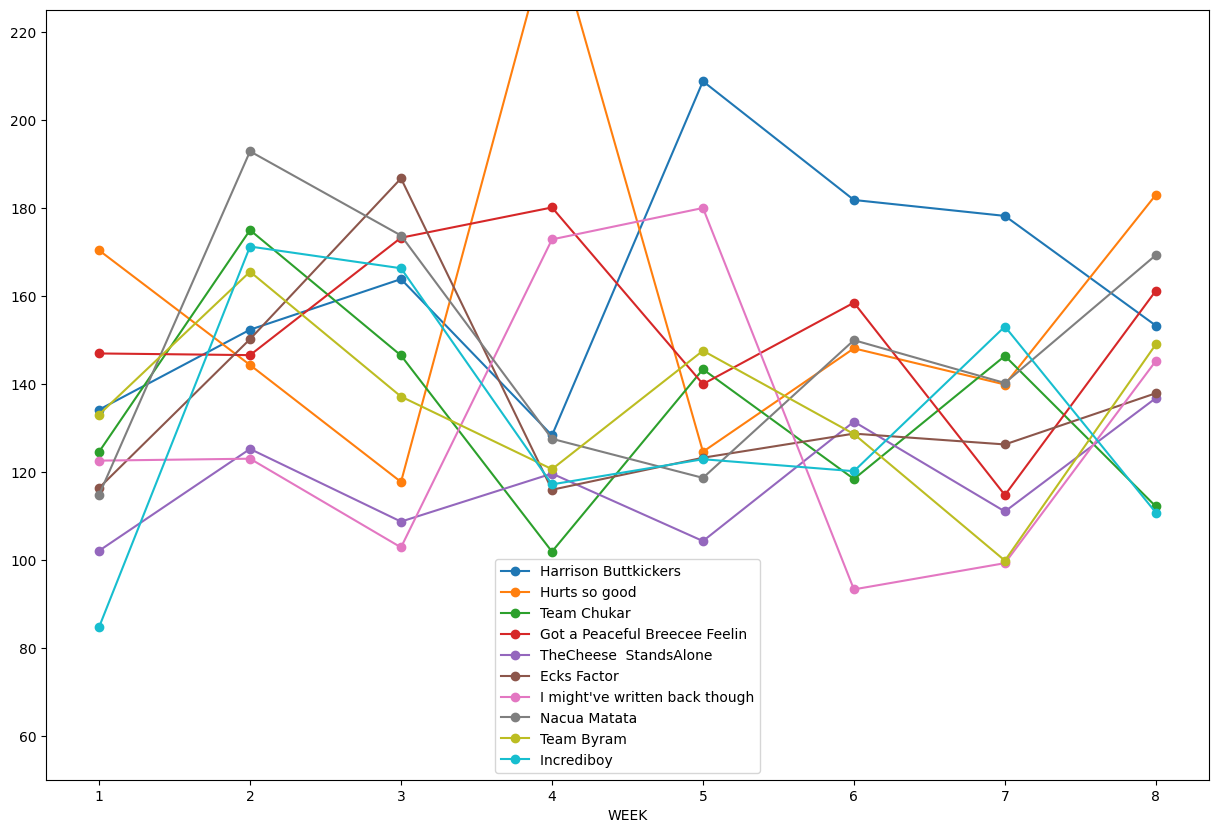

In [50]:
full_schedule.pivot(index='WEEK',columns='TEAM',values='SCORE').plot(figsize=(15,10), marker="o")
plt.ylim([50,225])
plt.legend(loc='best',labels=teams_df['FULL_NAME'])

## Victory Margins

Looking at each weeks win/loss margins and comparing to league average scores

In [51]:
schedule_df.head()

,WEEK,ID,WINNER,AWAY_TEAM_ID,AWAY_TEAM_SCORE,HOME_TEAM_ID,HOME_TEAM_SCORE,TYPE,WINNING_SCORE,LOSING_SCORE,WINNING_TEAM,LOSING_TEAM
0,1,1,AWAY,9,114.74,6,102.04,Regular,114.74,102.04,9,6
1,1,2,HOME,8,122.52,5,146.88,Regular,146.88,122.52,5,8
2,1,3,HOME,7,116.32,4,124.52,Regular,124.52,116.32,4,7
3,1,4,AWAY,1,134.10,10,133.00,Regular,134.10,133.00,1,10
4,1,5,HOME,11,84.68,2,170.32,Regular,170.32,84.68,2,11


In [52]:
#calculate each players +/- margins and then merge together into a single df
interrim_margins_df = schedule_df.assign(AWAY_MARGIN = schedule_df['AWAY_TEAM_SCORE'] - schedule_df['HOME_TEAM_SCORE'],
                HOME_MARGIN = schedule_df['HOME_TEAM_SCORE'] - schedule_df['AWAY_TEAM_SCORE'])
away_margins_df = interrim_margins_df[['WEEK', 'AWAY_TEAM_ID', 'AWAY_MARGIN', 'TYPE']].rename(columns={'AWAY_TEAM_ID': 'TEAM_ID', 'AWAY_MARGIN': 'MARGIN'})
home_margins_df = interrim_margins_df[['WEEK', 'HOME_TEAM_ID', 'HOME_MARGIN', 'TYPE']].rename(columns={'HOME_TEAM_ID': 'TEAM_ID', 'HOME_MARGIN': 'MARGIN'})
margins_df=pd.concat([away_margins_df,home_margins_df],ignore_index=True, sort=False)

#output a single week for a sample of how this looks
margins_df[margins_df['WEEK']==1]

,WEEK,TEAM_ID,MARGIN,TYPE
0,1,9,12.70,Regular
1,1,8,-24.36,Regular
2,1,7,-8.20,Regular
3,1,1,1.10,Regular
4,1,11,-85.64,Regular
75,1,6,-12.70,Regular
76,1,5,24.36,Regular
77,1,4,8.20,Regular
78,1,10,-1.10,Regular
79,1,2,85.64,Regular


In [53]:
margins_df['TEAM_NAME'] = margins_df['TEAM_ID'].apply(getTeamName)
margins_df.head()

,WEEK,TEAM_ID,MARGIN,TYPE,TEAM_NAME
0,1,9,12.70,Regular,Nacua Matata
1,1,8,-24.36,Regular,I might've written back though
2,1,7,-8.20,Regular,Ecks Factor
3,1,1,1.10,Regular,Harrison Buttkickers
4,1,11,-85.64,Regular,Incrediboy


C:\Users\kblanken\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\kblanken\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\kblanken\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\kblanken\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_d

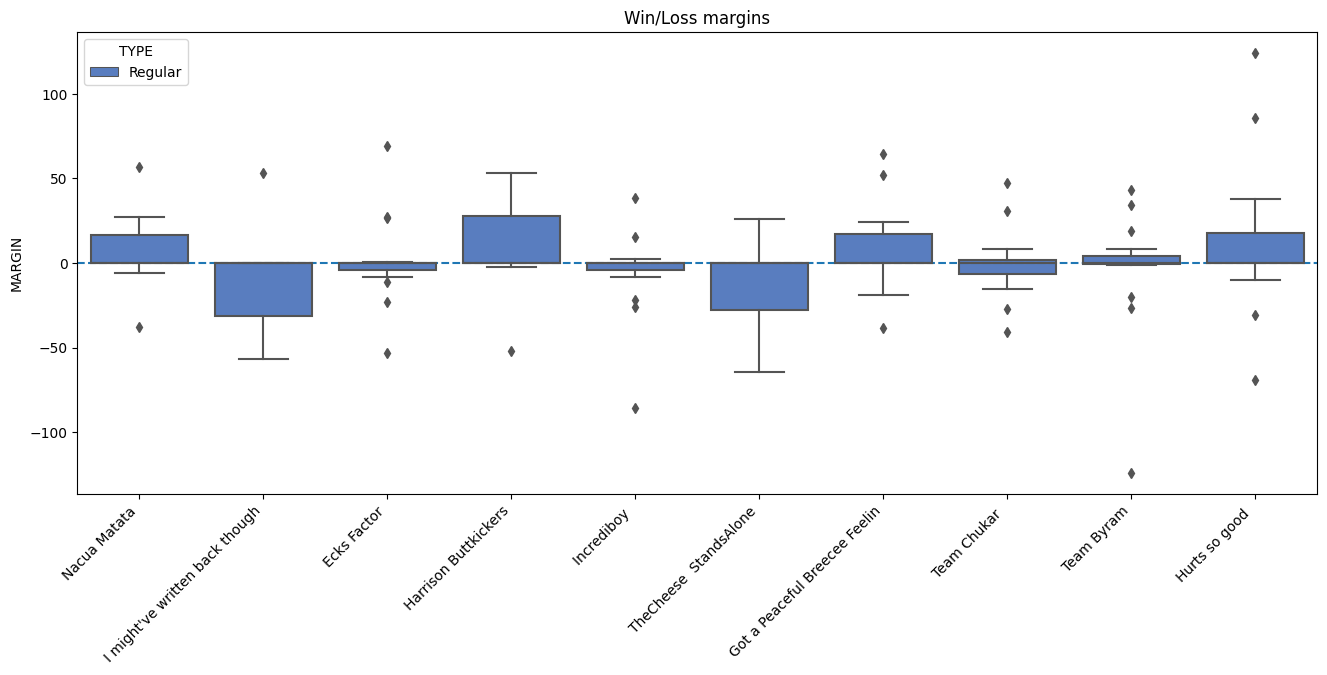

In [54]:
fig, ax = plt.subplots(1,1, figsize=(16,6))
sns.boxplot(x='TEAM_NAME', y='MARGIN', hue='TYPE',
            data=margins_df,
            palette='muted')
ax.axhline(0, ls='--')
ax.set_xlabel('')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
ax.set_title('Win/Loss margins')
plt.show()

## Individual Player Data

Trying to look at individual roster slots to start to get at projected vs actual and roster optimization

Define some constants for mappings

In [55]:
POSITION_MAPPING = {
    0: 'QB',
    4: 'WR',
    2: 'RB',
    23: 'FLEX',
    6: 'TE',
    16: 'D/ST',
    17: 'K',
    20: 'Bench',
    21: 'IR',
    '': 'NA'
}

def getPositionName(x):
    return POSITION_MAPPING[x]

ROSTER_SPOTS = {
    0: 2,
    4: 3,
    2: 2,
    23: 2,
    6: 1,
    16: 1,
    17: 1,
}

In [56]:
def load_week_player_data(week_to_check):  
    score_url = url + '?view=mMatchup&view=mMatchupScore'
    
    r = requests.get(score_url, cookies=cookies, params={"view": "mMatchupScore", "scoringPeriodId": week_to_check, "matchupPeriodId": week_to_check})
    d = r.json()
    
    #Initialize dictionaries
    player_name = []
    player_score_act = []
    player_score_proj = []
    player_roster_slot = []
    player_eligible_slots = []
    player_fantasy_team = []
    matchup_weeks = []
    
    for game in d['schedule']:
        if game['matchupPeriodId']==week_to_check:
            #Header to separate each game
            #print('-----------')
            #print(game['id'],"|",game['away']['teamId'],"|",game['home']['teamId'])
            #print('-----------')
            #Iterate over the home and away teams
            for team_type in ['away','home']:
                team_id=game[team_type]['teamId']
                #print(team_type)
                #Store the team roster and active roster
                #a_roster=team['rosterForMatchupPeriod']
                roster=game[team_type]['rosterForCurrentScoringPeriod']
                #print(roster['appliedStatTotal'])
                
                for entry in roster['entries']:
                    player_full_name = entry['playerPoolEntry']['player']['fullName']
                    player_lineup_slot = entry['lineupSlotId']
                    player_possible_slots = entry['playerPoolEntry']['player']['eligibleSlots']
                    for stat in entry['playerPoolEntry']['player']['stats']:
                        if stat['statSourceId'] == 0:
                            act = stat['appliedTotal']
                        elif stat['statSourceId'] == 1:
                            proj = stat['appliedTotal']
                        else:
                            print('Error')
                    #print(player_full_name,"|",POSITION_MAPPING[player_lineup_slot],"|",act,"|",proj)
                    matchup_weeks.append(week_to_check)
                    player_name.append(player_full_name)
                    player_score_act.append(act)
                    player_score_proj.append(proj)
                    player_roster_slot.append(player_lineup_slot)
                    player_eligible_slots.append(player_possible_slots)
                    player_fantasy_team.append(team_id)

    # Put the lists into a dictionary
    player_dict = {
        'Week': matchup_weeks,
        'PlayerName': player_name,
        'PlayerScoreActual': player_score_act,
        'PlayerScoreProjected': player_score_proj,
        'PlayerRosterSlotId': player_roster_slot,
        'PlayerEligibleSlots': player_eligible_slots,
        'PlayerFantasyTeam': player_fantasy_team
    }
    
    # Transform the dictionary into a DataFrame
    matchup_data_df = pd.DataFrame.from_dict(player_dict)
    
    # Initialize empty column for PlayerRosterSlot
    matchup_data_df['PlayerRosterSlot'] = ""
    
    # Replace the PlayerRosterSlot integers with position indicators
    matchup_data_df['PlayerRosterSlot'] = matchup_data_df['PlayerRosterSlotId'].apply(getPositionName)

    return matchup_data_df

In [57]:
matchup_data_df = load_week_player_data(1)
matchup_data_df.head()

,Week,PlayerName,PlayerScoreActual,PlayerScoreProjected,PlayerRosterSlotId,PlayerEligibleSlots,PlayerFantasyTeam,PlayerRosterSlot
0,1,Saquon Barkley,7.8,14.958647,2,"[2, 3, 23, 7, 20, 21]",9,RB
1,1,Stefon Diggs,21.2,12.952182,4,"[3, 4, 5, 23, 7, 20, 21]",9,WR
2,1,Garrett Wilson,11.9,13.634409,4,"[3, 4, 5, 23, 7, 20, 21]",9,WR
3,1,Jahmyr Gibbs,7.0,12.268121,2,"[25, 2, 3, 23, 7, 20, 21]",9,RB
4,1,James Conner,9.5,13.332085,23,"[2, 3, 23, 7, 20, 21]",9,FLEX


Now time to actually start figuring out min/maxes for each week

Need to figure out the possible roster combinations

In [58]:
def compute_pts(df):
    
    output_data = {}
    
    for index, team in teams_df.iterrows():
        tmid=team['ID']
        one_team_df = df[df['PlayerFantasyTeam']==tmid]
        
        pts = {'opts': 0, 'epts': 0, 'apts': 0}

        # ACTUAL STARTERS
        pts['apts'] = one_team_df.query('PlayerRosterSlot not in ["Bench", "IR"]').filter(['PlayerScoreActual']).sum().values[0]

        # OPTIMAL and ESPNPROJ STARTERS
        for method, cat in [('PlayerScoreActual', 'opts'), ('PlayerScoreProjected', 'epts')]:
            actflex = -100  # actual pts scored by flex
            proflex = -100  # "proj" pts scored by flex
            for pos, num in zip(POSITION_MAPPING, ROSTER_SPOTS):
                # actual points, sorted by either actual or proj outcome
                t = one_team_df.query('PlayerEligibleSlots == @pos').sort_values(by=method, ascending=False).filter(['PlayerScoreActual']).values[:,0]

                # projected points, sorted by either actual or proj outcome
                t2 = one_team_df.query('PlayerEligibleSlots == @pos').sort_values(by=method, ascending=False).filter(['PlayerScoreProjected']).values[:,0]

                # sum up points
                pts[cat] += t[:num].sum()

                # set the next best as flex
                if pos in ['RB', 'WR', 'TE'] and len(t) > num:
                    fn = t[num] if method=='PlayerScoreActual' else t2[num]
                    if fn > proflex:
                        actflex = t[num]
                        proflex = fn

            pts[cat] += actflex
        
        output_data[tmid] = pts
        
    return output_data

In [59]:
matchup_data_df = load_week_player_data(1)
data = compute_pts(matchup_data_df)

In [60]:
data

{1: {'opts': -100.0, 'epts': -100.0, 'apts': 134.1},
 2: {'opts': -100.0, 'epts': -100.0, 'apts': 170.32000000000002},
 4: {'opts': -100.0, 'epts': -100.0, 'apts': 124.52},
 5: {'opts': -100.0, 'epts': -100.0, 'apts': 146.88},
 6: {'opts': -100.0, 'epts': -100.0, 'apts': 102.04},
 7: {'opts': -100.0, 'epts': -100.0, 'apts': 116.32000000000001},
 8: {'opts': -100.0, 'epts': -100.0, 'apts': 122.52000000000002},
 9: {'opts': -100.0, 'epts': -100.0, 'apts': 114.74000000000001},
 10: {'opts': -100.0, 'epts': -100.0, 'apts': 133.0},
 11: {'opts': -100.0, 'epts': -100.0, 'apts': 84.68000000000002}}